# Rare-event estimation with importance sampling

**Gabriel Trabelsi**

The existing experiments compare direct Monte-Carlo with shifted proposals, first for a Gaussian tail and then for a Pareto tail.

**Academic context:** UM4MA379, Statistique Computationnelle, Sorbonne Université, Master 1, 2025-2026. Course: A. Guyader; practical sessions: M. Sangnier. Implementations and completed experiments by Gabriel Trabelsi, developed within the supplied exercise framework.

Figures and outputs are retained from the original notebook. Random draws and timings may differ on a new run; historical execution counters have been cleared.

**Runtime:** the original direct Gaussian experiment uses 100 million draws and the final Pareto experiment uses 50 million. Full execution requires substantial memory; see the reproduction notes.

In [ ]:
import numpy as np  # Vectors and matrices
from scipy import stats  # Probability distributions
import matplotlib.pyplot as plt  # Plots
from time import perf_counter
# Enable nice plots
import matplotlib as mpl
try:
    mpl.style.use('seaborn-v0_8')
except:
    mpl.style.use('seaborn')
mpl.rcParams['image.cmap'] = 'plasma'
nice_hist = dict(bins='auto', density=True, ec='w')


## 1. Gaussian rare event

The target is $P(Z\geq6)$ for a standard normal variable. The original direct estimate is zero, while the shifted-exponential estimate is close to the analytical reference.

In [ ]:
norm = stats.norm()
threshold = 6

p = norm.sf(threshold)

print('p =', p)


p = 9.865876450376948e-10


In [ ]:
n = 10**8  # int(1e8)

sample = norm.rvs(size=n)

estMC = (sample > threshold).mean()

print('Estimateur Monte-Carlo standard :', estMC)


Estimateur Monte-Carlo standard : 0.0


In [ ]:
exp = stats.expon(loc=threshold)
level = 0.05
n = 500000

sample = exp.rvs(size=n)
I_pref = np.exp(-sample**2/2 + sample - 6) / np.sqrt(2*np.pi)
est = np.mean(I_pref)

var_est = np.var(I_pref)

ic_bound = (var_est/n)**(1/2) * stats.norm.ppf(1-level/2)

print(est)

print(f"Estimateur : {est:1.2e}")
print(f"Intervalle de confiance asymptotique : [{est-ic_bound:1.2e},{est+ic_bound:1.2e}]")


9.865407869402759e-10
Estimateur : 9.87e-10
Intervalle de confiance asymptotique : [9.85e-10,9.88e-10]


## 2. Running estimates

The two proposals are a shifted exponential and a shifted Gaussian. The displayed intervals are pointwise asymptotic intervals, not simultaneous confidence bands.

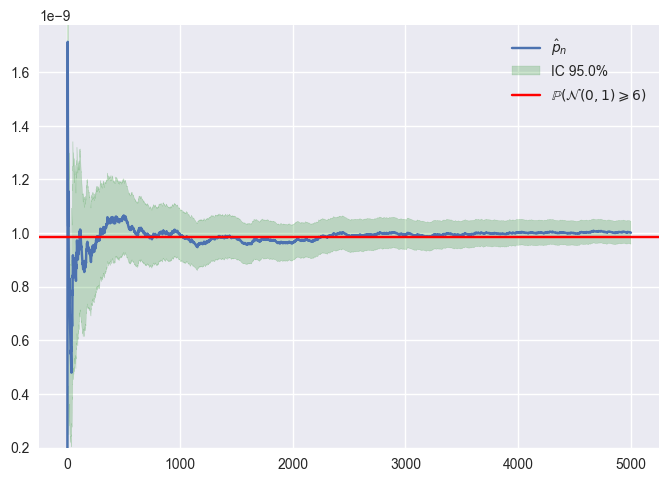

In [ ]:
exp = stats.expon(loc=threshold)
level = 0.05
n = 5000

sample = exp.rvs(size=n)
W = stats.norm.pdf(sample) / exp.pdf(sample)

k = np.arange(1, n+1)                            # 1, 2, ..., 500
est = np.cumsum(W) / k
var_est = np.cumsum(W**2) / k - est**2
ic_bound = (var_est/k)**(1/2) * stats.norm.ppf(1-level/2)

n_range = k

fig = plt.figure()
plt.plot(n_range, est, label="$\\hat{{p}}_n$")
plt.fill_between(n_range, est+ic_bound, est-ic_bound, color='green', alpha=0.2, label=f"IC {100*(1-level)}%")
plt.axhline(1 - norm.cdf(threshold), color='red', label=f"$\\mathbb{{P}}(\\mathcal{{N}}(0, 1) \\geqslant {threshold})$")
plt.ylim(.2*p, 1.8*p)
plt.legend()


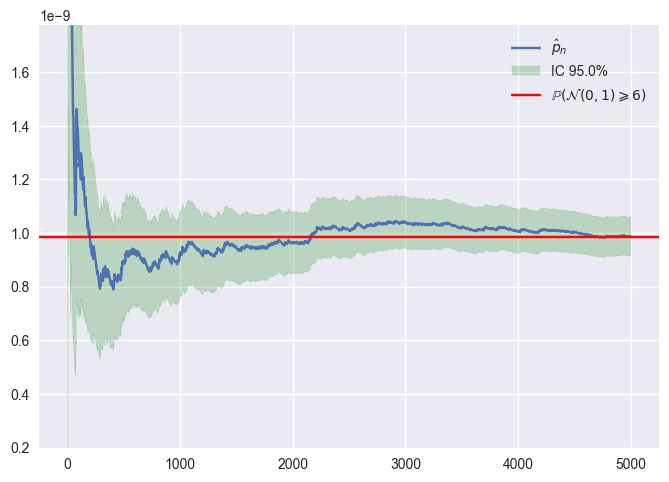

In [ ]:
g = stats.norm(loc=threshold)
level = 0.05
n = 5000

sample = g.rvs(size=n)
W = stats.norm.pdf(sample) / g.pdf(sample) * (sample>=6)

k = np.arange(1, n+1)                            # 1, 2, ..., 500
est = np.cumsum(W) / k
var_est = np.cumsum(W**2) / k - est**2
ic_bound = (var_est/k)**(1/2) * stats.norm.ppf(1-level/2)

n_range = k

fig = plt.figure()
plt.plot(n_range, est, label="$\\hat{{p}}_n$")
plt.fill_between(n_range, est+ic_bound, est-ic_bound, color='green', alpha=0.2, label=f"IC {100*(1-level)}%")
plt.axhline(1 - norm.cdf(threshold), color='red', label=f"$\\mathbb{{P}}(\\mathcal{{N}}(0, 1) \\geqslant {threshold})$")
plt.ylim(.2*p, 1.8*p)
plt.legend()


## 3. Pareto simulation and direct estimation

For shape 3 and scale 1, the probability of exceeding 10 is 0.001.

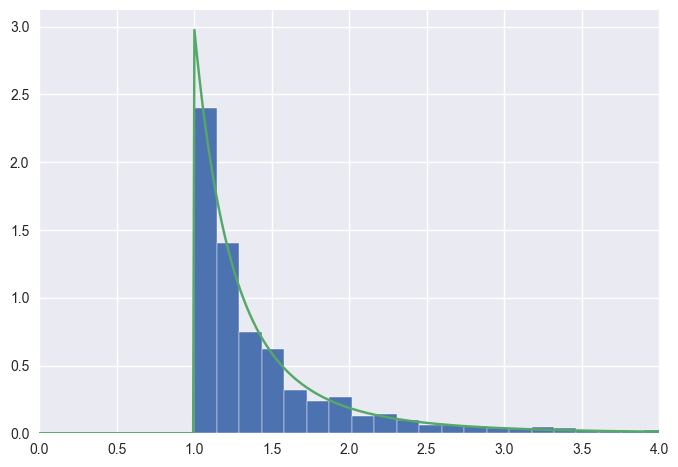

In [ ]:
unif = stats.uniform()
pareto = stats.pareto(b=3)

n = 1000
sample = unif.rvs(size=n)
x = sample**(-1/3)

t = np.linspace(0, 4, num=500)
plt.hist(x, label='Échantillon', **nice_hist)
plt.plot(t, pareto.pdf(t), label='Densité')
plt.xlim((0, t.max()));


0.000926


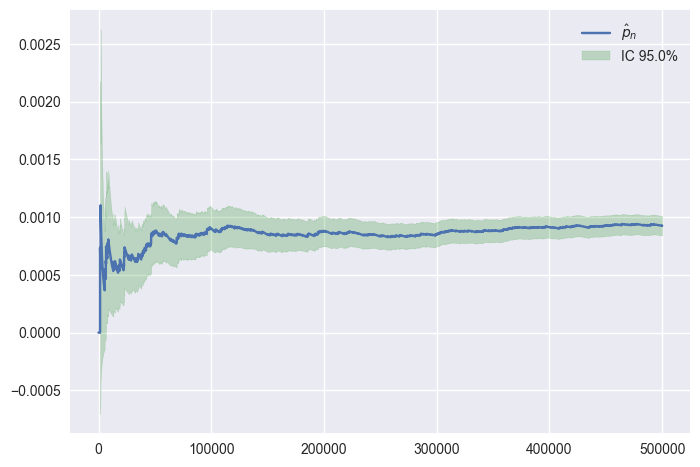

In [ ]:
g = stats.norm(loc=threshold)
level = 0.05
n = 500000

sample = unif.rvs(size=n)
W = (sample**(-1/3)>10)

k = np.arange(1, n+1)                            # 1, 2, ..., 500
est = np.cumsum(W) / k
var_est = np.cumsum(W**2) / k - est**2
ic_bound = (var_est/k)**(1/2) * stats.norm.ppf(1-level/2)

n_range = k

fig = plt.figure()
plt.plot(n_range, est, label="$\\hat{{p}}_n$")
plt.fill_between(n_range, est+ic_bound, est-ic_bound, color='green', alpha=0.2, label=f"IC {100*(1-level)}%")

plt.legend()

print(est[-1])


## 4. A poorly matched proposal

The light-tailed exponential proposal generates highly variable weights for the Pareto target. Its displayed normal-approximation interval is a diagnostic failure case, not a validated confidence statement.

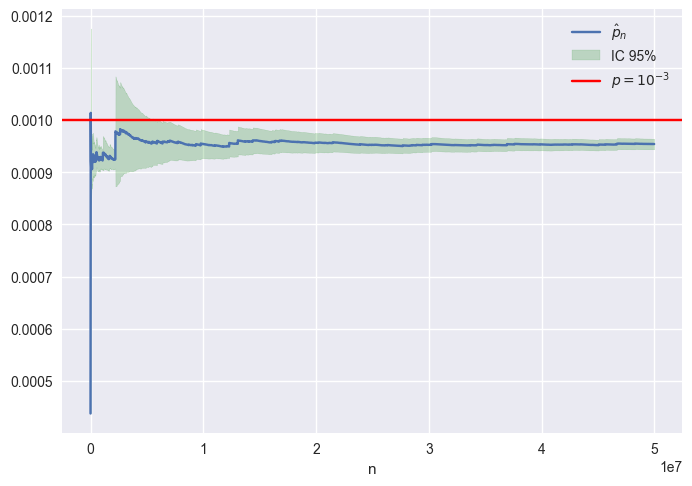

Estimation finale   : 9.541949e-04
Vraie valeur        : 1.000000e-03
Erreur relative     : 4.6 %
Poids max           : 1.173e+02
Poids moyen         : 9.542e-04
Ratio max/moyen     : 122884.5


In [ ]:
pareto = stats.pareto(b=3)          # au cas où il ne le serait plus
g = stats.expon(loc=10)             # exponentielle translatée en 10
level = 0.05
n = 500_00000
p_true = 1e-3                       # vraie valeur, pour référence

# --- Échantillonnage IS ---
sample = g.rvs(size=n)                             # Y_i ~ g
W = pareto.pdf(sample) / g.pdf(sample)             # poids f/g

# --- Estimateurs cumulatifs ---
k = np.arange(1, n+1)
est = np.cumsum(W) / k
var_est = np.cumsum(W**2) / k - est**2
ic_bound = np.sqrt(var_est/k) * stats.norm.ppf(1 - level/2)

# --- Affichage (sous-échantillonné) ---
step = max(1, n // 5000)
idx = np.arange(0, n, step)

fig = plt.figure()
plt.plot(k[idx], est[idx], label=r"$\hat{p}_n$")
plt.fill_between(k[idx], est[idx] - ic_bound[idx], est[idx] + ic_bound[idx],
                 color='green', alpha=0.2, label=f"IC {100*(1-level):.0f}%")
plt.axhline(p_true, color='red', label=r"$p = 10^{-3}$")
                # essentiel pour voir la structure des sauts
plt.xlabel('n')
plt.legend()
plt.show()

# --- Diagnostic quantitatif ---
print(f"Estimation finale   : {est[-1]:.6e}")
print(f"Vraie valeur        : {p_true:.6e}")
print(f"Erreur relative     : {abs(est[-1] - p_true)/p_true * 100:.1f} %")
print(f"Poids max           : {W.max():.3e}")
print(f"Poids moyen         : {W.mean():.3e}")
print(f"Ratio max/moyen     : {W.max() / W.mean():.1f}")


## Observations

The saved Gaussian experiment reports a reference probability of 9.865876450376948e-10, a direct estimate of zero and a shifted-exponential estimate of 9.865407869402759e-10. The Pareto example records a maximum-to-average weight ratio above 120,000. These are individual original runs, not repeated-run benchmarks.